## Cálculo de viabilidade de modelo de fraude

Este notebook avalia o ganho financeiro de um modelo antigo de detecção de fraude, variando o threshold (ponto de corte) do score.

**Premissas do exercício:**
- Venda legítima aprovada: ganho de 10% do valor da compra.
- Fraude aprovada (falso negativo): perda de 100% do valor da compra.
- Fraude reprovada (falso positivo evitado): perda evitada de 100% do valor.
- Venda legítima reprovada (falso positivo): perda de 10% do valor da compra.

**Fonte dos dados:** UNIPDS (Pós em Data Science e IA), arquivo `dados_modelo_antigo.xlsx`.

**Estrutura:** exploração inicial, leitura da distribuição do score, simulação de thresholds, refinamento e conclusão.

## Exploração inicial dos dados

Base com transações, valor da compra, score do modelo antigo de fraude e a classificação real (0 = legítima, 1 = fraude). Não há valores nulos. A classe fraude representa 5% da base, o que torna a acurácia uma métrica insuficiente para avaliar o modelo.

In [1]:
import pandas as pd

df = pd.read_excel('../data/raw/dados_modelo_antigo.xlsx')

print("Formato:", df.shape)
print("\nTipos:")
print(df.dtypes)
print("\nValores nulos:")
print(df.isna().sum())
print("\nDistribuição da classe fraude (0 = legítima, 1 = fraude):")
print(df['fraude'].value_counts())
print("\nPercentual de fraudes:", round(df['fraude'].mean() * 100, 2), "%")

Formato: (150000, 3)

Tipos:
valor_compra           float64
score_fraude_modelo      int64
fraude                   int64
dtype: object

Valores nulos:
valor_compra           0
score_fraude_modelo    0
fraude                 0
dtype: int64

Distribuição da classe fraude (0 = legítima, 1 = fraude):
fraude
0    142500
1      7500
Name: count, dtype: int64

Percentual de fraudes: 5.0 %


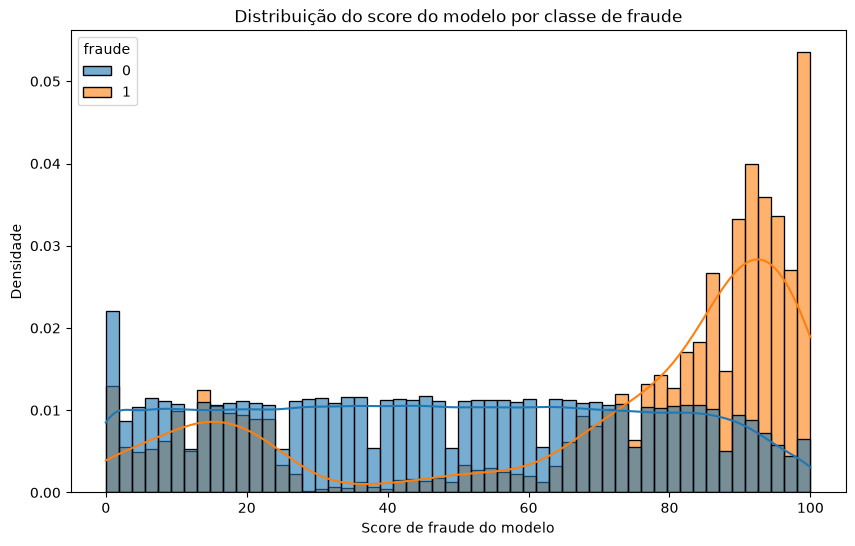

Total de transações aprovadas: 78792
Fraudes aprovadas (falso negativo): 1787
Legítimas reprovadas (falso positivo): 65495


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='score_fraude_modelo',
    hue='fraude',
    stat='density',
    common_norm=False,
    kde=True,
    alpha=0.6,
)

plt.title('Distribuição do score do modelo por classe de fraude')
plt.xlabel('Score de fraude do modelo')
plt.ylabel('Densidade')
plt.show()

aprovadas = df['score_fraude_modelo'] <= threshold
reprovadas = ~aprovadas

print("Total de transações aprovadas:", aprovadas.sum())
print("Fraudes aprovadas (falso negativo):", (aprovadas & (df['fraude'] == 1)).sum())
print("Legítimas reprovadas (falso positivo):", (reprovadas & (df['fraude'] == 0)).sum())


## Leitura da distribuição do score

- **Azul (fraude = 0):** transações legítimas. Concentram-se em scores baixos e são distribuídas de forma quase uniforme até cerca de 75.

- **Laranja (fraude = 1):** fraudes. Concentram-se em scores altos, sobretudo entre 85 e 100.

- **Zona de sobreposição (aproximadamente 70 a 85):** as duas classes aparecem juntas. Um corte nessa região bloqueia fraudes e compras legítimas ao mesmo tempo, então o threshold precisa ser escolhido com base no custo financeiro, e não só na separação visual.

## Testes com thresholds específicos

Antes da simulação completa, testamos alguns thresholds individualmente, observando o gráfico e as contagens de acertos e erros.

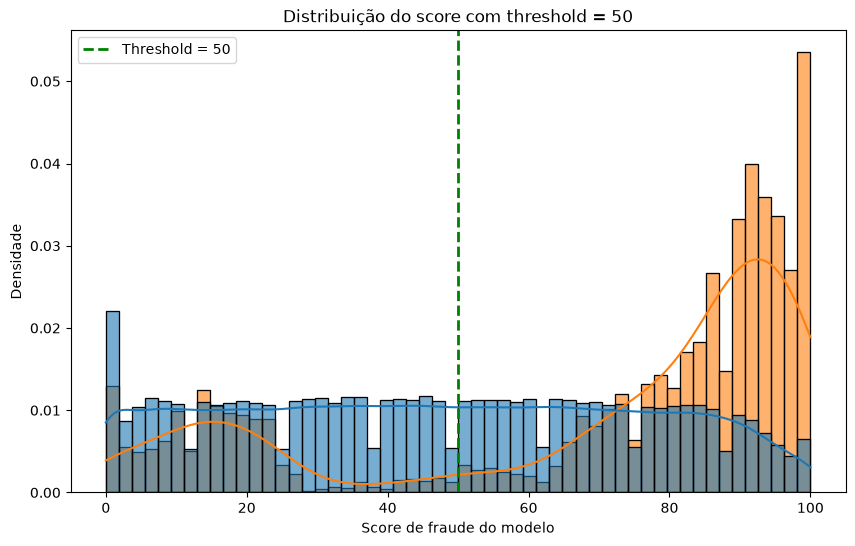

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

threshold = 50

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='score_fraude_modelo',
    hue='fraude',
    stat='density',
    common_norm=False,
    kde=True,
    alpha=0.6,
)

plt.axvline(x=threshold, color='green', linestyle='--', linewidth=2,
            label=f'Threshold = {threshold}')

plt.title(f'Distribuição do score com threshold = {threshold}')
plt.xlabel('Score de fraude do modelo')
plt.ylabel('Densidade')
plt.legend()
plt.show()

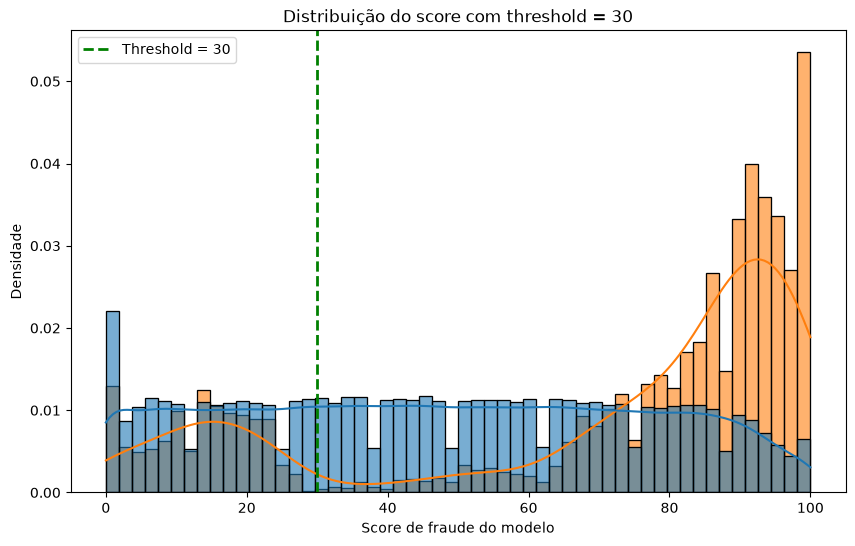

Total de transações aprovadas: 48786
Fraudes aprovadas (falso negativo): 1607
Legítimas reprovadas (falso positivo): 95321


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

threshold = 30

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='score_fraude_modelo',
    hue='fraude',
    stat='density',
    common_norm=False,
    kde=True,
    alpha=0.6,
)

plt.axvline(x=threshold, color='green', linestyle='--', linewidth=2,
            label=f'Threshold = {threshold}')

plt.title(f'Distribuição do score com threshold = {threshold}')
plt.xlabel('Score de fraude do modelo')
plt.ylabel('Densidade')
plt.legend()
plt.show()


aprovadas = df['score_fraude_modelo'] <= threshold
reprovadas = ~aprovadas

print("Total de transações aprovadas:", aprovadas.sum())
print("Fraudes aprovadas (falso negativo):", (aprovadas & (df['fraude'] == 1)).sum())
print("Legítimas reprovadas (falso positivo):", (reprovadas & (df['fraude'] == 0)).sum())



## Simulação do threshold 30

Aplicamos um corte em score ≤ 30 para aprovar a transação. Resultados:

- Transações aprovadas: 48.786 de 150.000
- Fraudes aprovadas (falso negativo): 1.607, de 7.500
- Legítimas reprovadas (falso positivo): 95.321, de 142.500

Pelas regras do exercício, o ganho líquido foi de R$ 112.088,09. Esse valor é positivo, mas ainda não sabemos se é o melhor possível. O próximo passo é testar outros thresholds e comparar o ganho líquido de cada um.

In [33]:
ganho_legitimas_aprovadas = (df.loc[aprovadas & (df['fraude'] == 0), 'valor_compra'] * 0.10).sum()
perda_fraudes_aprovadas = df.loc[aprovadas & (df['fraude'] == 1), 'valor_compra'].sum()
ganho_fraudes_reprovadas = df.loc[reprovadas & (df['fraude'] == 1), 'valor_compra'].sum()
perda_legitimas_reprovadas = (df.loc[reprovadas & (df['fraude'] == 0), 'valor_compra'] * 0.10).sum()

ganho_liquido = ganho_legitimas_aprovadas - perda_fraudes_aprovadas + ganho_fraudes_reprovadas - perda_legitimas_reprovadas

print(f"Threshold {threshold}")
print(f"Ganho em vendas legítimas aprovadas: R$ {ganho_legitimas_aprovadas:,.2f}")
print(f"Perda com fraudes aprovadas: R$ {perda_fraudes_aprovadas:,.2f}")
print(f"Perda evitada com fraudes reprovadas: R$ {ganho_fraudes_reprovadas:,.2f}")
print(f"Perda com legítimas reprovadas: R$ {perda_legitimas_reprovadas:,.2f}")
print(f"Ganho líquido: R$ {ganho_liquido:,.2f}")

Threshold 30
Ganho em vendas legítimas aprovadas: R$ 175,810.55
Perda com fraudes aprovadas: R$ 94,342.12
Perda evitada com fraudes reprovadas: R$ 452,929.00
Perda com legítimas reprovadas: R$ 422,309.35
Ganho líquido: R$ 112,088.09


## Simulação de thresholds de 0 a 100

Para cada threshold de 0 a 100, de 5 em 5, calculamos quantas transações são aprovadas e o ganho líquido pelas regras do exercício.

In [34]:
resultados = []

for t in range(0, 101, 5):
    aprov = df['score_fraude_modelo'] <= t
    rep = ~aprov

    g_leg = (df.loc[aprov & (df['fraude'] == 0), 'valor_compra'] * 0.10).sum()
    p_fraude = df.loc[aprov & (df['fraude'] == 1), 'valor_compra'].sum()
    g_fraude = df.loc[rep & (df['fraude'] == 1), 'valor_compra'].sum()
    p_leg = (df.loc[rep & (df['fraude'] == 0), 'valor_compra'] * 0.10).sum()

    resultados.append({
        'threshold': t,
        'aprovadas': aprov.sum(),
        'ganho_liquido': g_leg - p_fraude + g_fraude - p_leg,
    })

df_resultados = pd.DataFrame(resultados)
df_resultados

,threshold,aprovadas,ganho_liquido
0,0,4969,-29169.380
1,5,11168,-818.812
2,10,18816,21094.178
3,15,26318,33910.664
4,20,33874,54433.444
5,25,41268,66260.396
6,30,48786,112088.088
7,35,56244,165835.716
8,40,63737,219127.236
9,45,71348,269573.464


## Escolha do threshold

Testamos thresholds de 0 a 100, de 5 em 5, calculando o ganho líquido de cada um pelas regras do exercício.

O maior ganho líquido ocorre em **threshold = 75**, com R$ 479.009,36. Os thresholds 70 e 80 ficam próximos (R$ 464.135,32 e R$ 471.164,95), o que indica um platô na faixa de 70 a 80.

Como a grade foi de 5 em 5, o valor exato ótimo pode estar entre os testados. Também consideramos que o ganho líquido não captura custos indiretos, como insatisfação de clientes bloqueados, então a escolha final deve equilibrar o resultado financeiro com esses fatores.

## Refinamento entre 70 e 80

Testamos cada threshold entre 70 e 80, de 1 em 1, para confirmar o ponto de maior ganho líquido.

In [35]:
resultados_finos = []

for t in range(70, 81):
    aprov = df['score_fraude_modelo'] <= t
    rep = ~aprov

    g_leg = (df.loc[aprov & (df['fraude'] == 0), 'valor_compra'] * 0.10).sum()
    p_fraude = df.loc[aprov & (df['fraude'] == 1), 'valor_compra'].sum()
    g_fraude = df.loc[rep & (df['fraude'] == 1), 'valor_compra'].sum()
    p_leg = (df.loc[rep & (df['fraude'] == 0), 'valor_compra'] * 0.10).sum()

    resultados_finos.append({
        'threshold': t,
        'aprovadas': aprov.sum(),
        'ganho_liquido': g_leg - p_fraude + g_fraude - p_leg,
    })

df_finos = pd.DataFrame(resultados_finos)
df_finos

,threshold,aprovadas,ganho_liquido
0,70,108811,464135.322
1,71,110293,468509.706
2,72,111767,473509.338
3,73,113317,476683.698
4,74,114766,476095.312
5,75,116330,479009.360
6,76,117813,476466.016
7,77,119269,477002.346
8,78,120707,474612.526
9,79,122169,477220.554


## Conclusão

Após testar thresholds de 0 a 100 (de 5 em 5) e refinar entre 70 e 80 (de 1 em 1), o maior ganho líquido ocorre em **threshold = 75**, com R$ 479.009,36.

Em comparação, o threshold 30 (usado como primeiro teste) gerou R$ 112.088,09, e o threshold 0 teve prejuízo. Isso mostra que escolher o corte é uma decisão financeira, e não apenas estatística: cortes baixos bloqueiam muitas compras legítimas, e cortes altos deixam passar fraudes.

Limitações:
- O ganho líquido considera apenas as regras de percentual definidas no exercício (10% de margem e 100% de perda em fraude). Custos indiretos, como insatisfação de clientes bloqueados e perda de clientes, não estão incluídos.
- O resultado depende das premissas de 10% e 100%. Se elas mudarem, o threshold ótimo pode mudar.

## Fonte dos dados

Base disponibilizada pela UNIPDS (Pós em Data Science e IA), para fins de estudo.